# Fine-resolution grids and a rift with vertical walls

This notebook repeats `fine_grid_demo.ipynb` for a rift with vertical walls.  The rift has the same depth and width as in that notebook, and the data, grids, and constraint weights are the same, but the trough's walls and ends are steps.  Neither the coarse grids nor the fine grids can represent a step: the fine grids have 25 m and 50 m nodes, and their smoothness constraints limit how steeply the model can change.  The notebook shows what happens when neither model can match the data exactly.  See `fine_grid_demo.ipynb` for a description of the fine-grid options, and the README for setup instructions.

## The model

Outside the region $R$, the model is the usual coarse model, $z_m = z_0 + \delta z$.  Inside $R$, we add a fine-resolution DEM, $z_{0,f}$, and a fine-resolution height-change field, $\delta z_f$:

$$
z_m(x, y, t) = z_0(x, y) + \delta z(x, y, t) + z_{0,f}(x, y) + \delta z_f(x, y, t),
\qquad \delta z_f(x, y, t_{ref}) = 0 .
$$

Here $t_{ref}$ is the time of the reference epoch, at which the coarse $\delta z$ is also zero.  The fine grids have model parameters only at nodes inside $R$, and only data near $R$ involve them.

The fine fields have their own smoothness constraints, usually much weaker than those on the coarse fields.  For example, the curvature constraint on $z_{0,f}$ adds

$$
R_{0,f} = \int_R \frac{\left(\partial_{xx} z_{0,f}\right)^2 + 2\left(\partial_{xy} z_{0,f}\right)^2 + \left(\partial_{yy} z_{0,f}\right)^2}{E_{xx,f}^2}\, dA
$$

to the misfit, alongside $(r/\sigma)^2$ for each datum, where $E_{xx,f}$ is `fine_grid_args['E_RMS']['d2z0_dx2']`.  A small $E_{xx,f}$ makes $z_{0,f}$ stiff; a large one lets it follow the data.  The finite-difference equations are centered on the nodes inside $R$, and nodes outside $R$ enter them as zero.  The constraints therefore pull the fine fields towards zero at the edge of $R$, so features larger than the region go into the coarse fields, and the fine fields resolve what the coarse fields cannot.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import shapely
import pointCollection as pc
from LSsurf.smooth_fit import smooth_fit
from LSsurf.lin_op import lin_op
import time

# plot styling: text in ink, coarse fit in blue, coarse+fine fit in orange, diverging maps blue-gray-red
ink, ink2 = '#0b0b0b', '#52514e'
c_coarse, c_fine = '#2a78d6', '#eb6834'
div_cmap = LinearSegmentedColormap.from_list('div', ['#104281', '#3987e5', '#9ec5f4', '#f0efec',
                                                     '#f2a9a8', '#e34948', '#9c2a2a'])
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': ink2, 'axes.labelcolor': ink2, 'xtick.color': ink2, 'ytick.color': ink2})

## A synthetic rift

We work in an 8 km × 8 km domain over four years, in a Lagrangian frame, so the rift does not move with the ice.  The true surface is a smooth background that thins at about 0.5 m/yr, plus a rift: a flat-floored trough with vertical walls along a curved line that deepens, widens, and propagates east,

$$
r(x, y, t) = \begin{cases} -D(t) & \text{if } |d| < w(t) \text{ and } -2.4\ \text{km} < x < x_{tip}(t) \\ 0 & \text{otherwise} \end{cases}
$$

$$
D(t) = 4\,(4 + 2t)\ \text{m}, \qquad w(t) = 60 + 20t\ \text{m}.
$$

Here $d$ is the distance from the rift's center line, and the rift tip is at $x_{tip}(t) = 0.4 + 0.5t$ km.  $D$ and $w$ are the same as in `fine_grid_demo.ipynb`: the trough is 16 m deep at t = 0 and 48 m deep at t = 4 yr, and its walls are $w$ = 60 to 140 m from the center line.  The walls move outward by 20 m/yr, and as the tip passes a point, the floor there drops by tens of meters at once.  A trough this narrow cannot be represented on the coarse grids, which have 200 m nodes for $z_0$ and 1 km nodes for $\delta z$.

The data are near-north-south altimetry tracks (six per quarter, 20 m along-track, $\sigma$ = 0.1 m) and four DEM strips (40 m posting, $\sigma$ = 0.5 m).  Between DEM epochs, only the tracks sample the rift.

In [2]:
rng = np.random.default_rng(42)
HW = 4000.                 # half-width of the domain, m
t_ref = 2.                 # time of the reference epoch, yr

def rift_y(x):
    # y coordinate of the rift's center line
    return -500 + 800*np.sin(2*np.pi*x/12000)

def rift(x, y, t):
    slope = 800*2*np.pi/12000*np.cos(2*np.pi*x/12000)
    d = (y - rift_y(x))/np.sqrt(1+slope**2)
    x_tip = 400 + 500*t
    # vertical walls at |d| = w(t), and abrupt ends
    inside = (np.abs(d) < 60+20*t) & (x > -2400) & (x < x_tip)
    return -4*(4+2*t)*inside

def z_true(x, y, t):
    z_bg = 50 + 2e-3*x - 1e-3*y + 3*np.cos(2*np.pi*x/6000)*np.cos(2*np.pi*y/7000)
    dz_bg = -0.5*t*(1 + 0.5*np.sin(2*np.pi*(x+y)/9000))
    return z_bg + dz_bg + rift(x, y, t)

# altimetry: six near-N-S tracks per quarter
D = []
for k in range(16):
    for track in range(6):
        t = 0.125 + 0.25*k + rng.uniform(-0.1, 0.1)
        y = np.arange(-HW, HW, 20.)
        x = rng.uniform(-HW, HW) + 0.05*y
        D.append(pc.data().from_dict({'x': x, 'y': y, 'time': np.zeros_like(x)+t,
                                      'sigma': np.zeros_like(x)+0.1, 'sensor': np.zeros_like(x)}))
# DEM strips, 5 km wide
DEM_times, DEM_xc = [0.3, 1.6, 2.9, 3.8], [-1000, 1200, 0, 800]
for t, xc in zip(DEM_times, DEM_xc):
    xg, yg = [jj.ravel() for jj in np.meshgrid(np.arange(xc-2500, xc+2500, 40.), np.arange(-HW, HW, 40.))]
    xg, yg = xg + rng.uniform(-20, 20, xg.size), yg + rng.uniform(-20, 20, yg.size)
    D.append(pc.data().from_dict({'x': xg, 'y': yg, 'time': np.zeros_like(xg)+t,
                                  'sigma': np.zeros_like(xg)+0.5, 'sensor': np.ones_like(xg)}))
data = pc.data().from_list(D)
data.index((np.abs(data.x) < HW-1) & (np.abs(data.y) < HW-1))
data.assign(z=z_true(data.x, data.y, data.time) + rng.normal(size=data.size)*data.sigma)
print(f'{data.size} data: {np.sum(data.sensor==0)} altimetry, {np.sum(data.sensor==1)} DEM')

137716 data: 37971 altimetry, 99745 DEM


The region $R$ is the rift's full path buffered by 400 m.  In a Lagrangian fit the ice that will rift stays in place, so $R$ includes the part of the path that the tip reaches only late in the record.  The region can be a shapely geometry (as here), a gridded mask, or a vector or raster file.

We also define an averaging box, $B$, around the rift.  Later we compare the mean height change in $B$ from each fit with the true mean change.

region area: 4.9 km^2 of 64 km^2


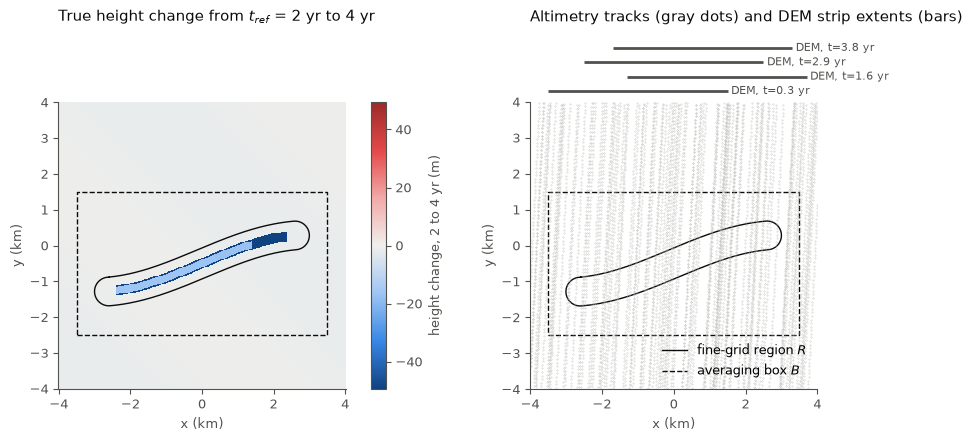

In [3]:
x_path = np.arange(-2600, 2601, 50.)
region = shapely.LineString(np.c_[x_path, rift_y(x_path)]).buffer(400)
print(f'region area: {region.area/1e6:.1f} km^2 of {(2*HW)**2/1e6:.0f} km^2')

# averaging box: the 1-km cells of the dz nodes with |x| <= 3 km, -2 km <= y <= 1 km
box_bounds = {'x': [-3500, 3500], 'y': [-2500, 1500]}
xm = np.arange(-HW, HW+1, 100.)
xmg, ymg = np.meshgrid(xm, xm)
box = pc.grid.data().from_dict({'x': xm, 'y': xm, 'z': ((np.abs(xmg) <= 3500) & (ymg >= -2500) & (ymg <= 1500)).astype(float)})

fig, ax = plt.subplots(1, 2, figsize=(10, 4.3), constrained_layout=True)
xx = np.arange(-HW, HW+1, 25.)
xg, yg = np.meshgrid(xx, xx)
change = z_true(xg, yg, 4.) - z_true(xg, yg, t_ref)
lim = np.abs(change).max()
h = ax[0].pcolormesh(xx/1000, xx/1000, change, cmap=div_cmap, norm=TwoSlopeNorm(0, -lim, lim), shading='nearest')
fig.colorbar(h, ax=ax[0], label='height change, 2 to 4 yr (m)')
ax[0].set_title('True height change from $t_{ref}$ = 2 yr to 4 yr', loc='left', color=ink, pad=58)
for this_ax in ax:
    this_ax.plot(*np.array(region.exterior.xy)/1000, color=ink, lw=1, label='fine-grid region $R$')
    this_ax.plot(np.array(box_bounds['x'])[[0, 1, 1, 0, 0]]/1000, np.array(box_bounds['y'])[[0, 0, 1, 1, 0]]/1000,
                 color=ink, lw=1, ls='--', label='averaging box $B$')
    this_ax.set_aspect('equal')
    this_ax.set_xlabel('x (km)'); this_ax.set_ylabel('y (km)')
alt = data[data.sensor == 0]
ax[1].plot(alt.x[::5]/1000, alt.y[::5]/1000, '.', color='#b8b7b1', ms=0.5)
# each DEM strip covers the full y range; show its x extent above the domain
for i, (t, xc) in enumerate(zip(DEM_times, DEM_xc)):
    y_bar = (HW + 300 + 400*i)/1000
    ax[1].plot([(xc-2500)/1000, (xc+2500)/1000], [y_bar, y_bar], color=ink2, lw=2, solid_capstyle='butt', clip_on=False)
    ax[1].text((xc+2600)/1000, y_bar, f'DEM, t={t} yr', va='center', fontsize=8, color=ink2, clip_on=False)
ax[1].set_xlim(-HW/1000, HW/1000); ax[1].set_ylim(-HW/1000, HW/1000)
ax[1].set_title('Altimetry tracks (gray dots) and DEM strip extents (bars)', loc='left', color=ink, pad=58)
ax[1].legend(loc='lower right', frameon=False);

## Fitting with and without the fine grids

We run the same fit twice.  The coarse fit uses a 200 m $z_0$ grid and a 1 km, quarterly $\delta z$ grid.  The second fit adds fine grids in $R$: 25 m nodes for $z_{0,f}$ and 50 m nodes for $\delta z_f$, with the same quarterly epochs.  The `spacing` entry takes either one number for both fine grids, or a dict like `smooth_fit`'s own `spacing` argument.

The fine-grid constraints are much weaker than the coarse ones: the $z_{0,f}$ curvature weight is 50 times the coarse one, and the $\delta z_f$ rate-curvature weight is 100 times the coarse one.  We also ask for the mean height change in the box $B$ through `avg_masks`, and for error estimates from the fine-grid fit.

In [4]:
E_RMS = {'d2z0_dx2': 0.02, 'dz0_dx': 0.02*2500, 'd3z_dx2dt': 0.003, 'd2z_dxdt': 0.003*2500, 'd2z_dt2': 5000}
fit_args = dict(data=data, ctr={'x': 0., 'y': 0., 't': 2.}, W={'x': 2*HW, 'y': 2*HW, 't': 4.},
                spacing={'z0': 200, 'dz': 1000, 'dt': 0.25}, E_RMS=E_RMS, reference_epoch=8,
                max_iterations=5, dzdt_lags=[1], avg_masks={'box': box}, solver='cholmod', VERBOSE=False)

fine_grid_args = {'region': region,
                  'spacing': {'z0': 25, 'dz': 50},
                  'E_RMS': {'d2z0_dx2': 1.0, 'd3z_dx2dt': 0.3, 'd2z_dt2': 100}}
t0=time.time()
S_coarse = smooth_fit(**fit_args)
dt_coarse = time.time()-t0
t0=time.time()
S_fine = smooth_fit(**fit_args, fine_grid_args=fine_grid_args, compute_E=True)
dt_fine = time.time()-t0

for label, S in [('coarse', S_coarse), ('coarse + fine', S_fine)]:
    in_R = shapely.contains_xy(region, S['data'].x, S['data'].y)
    print(f"{label:14s}: {S['m']['all'].size:6d} model parameters; "
          f"{100*np.mean(~S['data'].three_sigma_edit[in_R]):4.1f}% of the data in R rejected as outliers")
for name in ['z0_fine', 'dz_fine']:
    grid = S_fine['grids'][name]
    print(f"{name}: {grid.delta[0]:.0f} m nodes, {grid.N_active} parameters")
print(f'timing:\n\tcoarse:{dt_coarse:3.2f} s\n\tfine:{dt_fine:3.2f} s')

coarse        :   3058 model parameters; 42.3% of the data in R rejected as outliers
coarse + fine :  41997 model parameters; 14.9% of the data in R rejected as outliers
z0_fine: 25 m nodes, 7787 parameters
dz_fine: 50 m nodes, 31152 parameters
timing:
	coarse:2.09 s
	fine:80.81 s


The fine grids add about 39,000 parameters to the 3,000 of the coarse model; a model with the fine grids' resolution over the whole domain would have about 540,000.  With error estimates, the coarse+fine fit takes about 80 s, compared with about 2 s for the coarse fit (the timings are printed above); most of the difference is the error calculation.  The coarse fit rejects 42% of the data in $R$ as outliers, and the coarse+fine fit rejects 15%, most of them near the walls (see below).

## How well do the fits recover the surface?

We evaluate each model on a 25 m grid of points, $\mathbf{x}_i$, and compare it with the true surface:

$$
\epsilon_{RMS}(t) = \sqrt{\frac{1}{N}\sum_{i=1}^{N} \left[ z_m(\mathbf{x}_i, t) - z_{true}(\mathbf{x}_i, t) \right]^2 },
$$

separately for the points inside and outside $R$.  To evaluate the model at arbitrary points, we build the same interpolation operators that `smooth_fit` uses for the data; for the fine grids, `restrict_to_active` keeps only the nodes inside $R$.

coarse         inside R: 6.46 to 20.43 m, median 8.42 m
coarse         outside R: 0.07 to 0.16 m, median 0.08 m
coarse + fine  inside R: 5.36 to 9.70 m, median 6.48 m
coarse + fine  outside R: 0.07 to 0.16 m, median 0.08 m


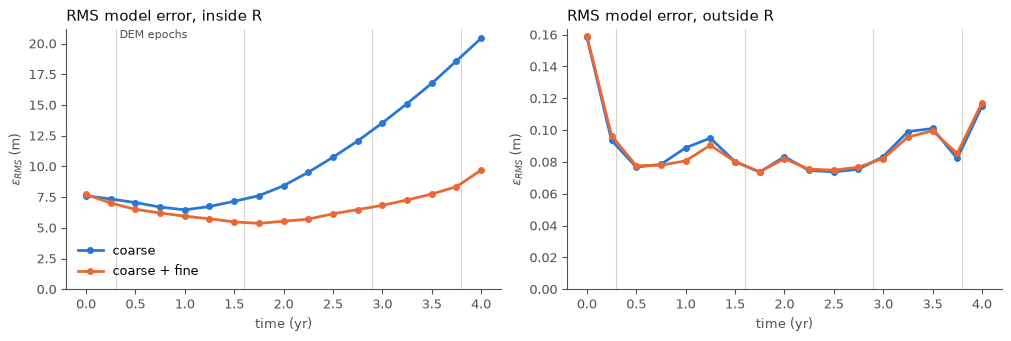

In [5]:
def model_at(S, x, y, t):
    # evaluate the full model (coarse + fine) at points (x, y, t)
    grids, m0 = S['grids'], S['m']['all']
    G = lin_op(grids['z0']).interp_mtx([y, x])
    G.add(lin_op(grids['dz']).interp_mtx([y, x, t]))
    for name, pts in [('z0_fine', [y, x]), ('dz_fine', [y, x, t])]:
        if name in grids:
            G.add(lin_op(grids[name]).interp_mtx(pts, bounds_error=False).restrict_to_active(drop_rows=False))
    return G.toCSR(row_N=x.size, col_N=m0.size).dot(m0)

xe, ye = [jj.ravel() for jj in np.meshgrid(np.arange(-HW+12.5, HW, 25.), np.arange(-HW+12.5, HW, 25.))]
in_region = shapely.contains_xy(region, xe, ye)
t_eval = np.arange(0, 4.01, 0.25)
rms_err = {}
for label, S in [('coarse', S_coarse), ('coarse + fine', S_fine)]:
    rms_err[label] = {'inside R': [], 'outside R': []}
    for t in t_eval:
        err = model_at(S, xe, ye, np.zeros_like(xe)+t) - z_true(xe, ye, t)
        rms_err[label]['inside R'].append(np.sqrt(np.mean(err[in_region]**2)))
        rms_err[label]['outside R'].append(np.sqrt(np.mean(err[~in_region]**2)))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3), constrained_layout=True)
for this_ax, where in zip(ax, ['inside R', 'outside R']):
    for label, color in [('coarse', c_coarse), ('coarse + fine', c_fine)]:
        this_ax.plot(t_eval, rms_err[label][where], color=color, lw=2, marker='o', ms=4, label=label)
    for t in DEM_times:
        this_ax.axvline(t, color='#d6d5d0', lw=0.8, zorder=0)
    this_ax.set_title(f'RMS model error, {where}', loc='left', color=ink)
    this_ax.set_xlabel('time (yr)'); this_ax.set_ylabel('$\\epsilon_{RMS}$ (m)')
    this_ax.set_ylim(bottom=0)
ax[0].legend(frameon=False)
ax[0].text(DEM_times[0], ax[0].get_ylim()[1], ' DEM epochs', color=ink2, va='top', fontsize=8)
for label in rms_err:
    for where in ['inside R', 'outside R']:
        v = np.array(rms_err[label][where])
        print(f'{label:14s} {where}: {v.min():.2f} to {v.max():.2f} m, median {np.median(v):.2f} m')

Inside $R$, the fine grids reduce the RMS error from 6.5 to 20.4 m (median 8.4 m) to 5.4 to 9.7 m (median 6.5 m), much less than for the rift with smooth walls.  Outside $R$, the two fits are equally good (0.07 to 0.16 m): the coarse fit rejects so many of the rift's data that the rift no longer distorts its coarse fields.

As in `fine_grid_demo.ipynb`, the coarse+fine model spreads the abrupt deepening at the tip over the whole record, so its errors are largest ahead of the tip early in the record.  At x = 2.2 km, where the tip arrives at t = 3.6 yr, the model is 61 m above the true surface at t = 0, and at t = 4 yr its trough is 21 m deep, where the true trough is 48 m deep.

The shaded-relief maps below show the north-south slope of the true surface and of the two fits at t = 2.9 yr, on the same gray scale.  The red line marks the location of the profiles that follow.

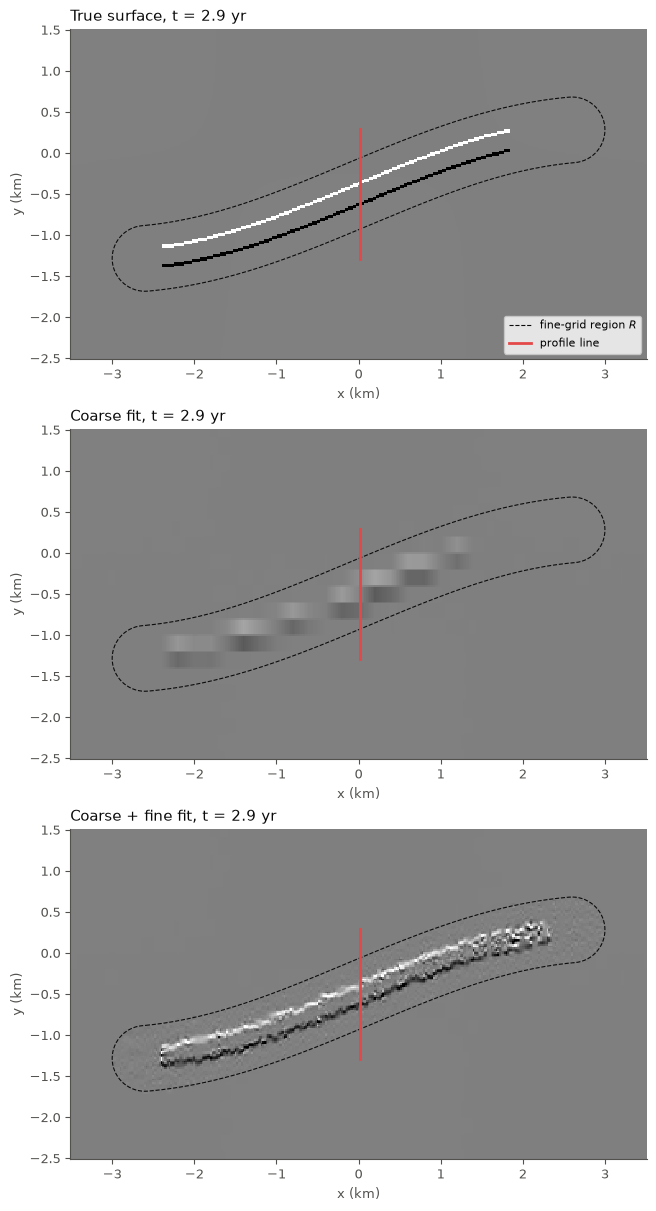

In [6]:
# location of the profiles shown below
x_prof = 12.5
ii = (xe == x_prof) & (np.abs(ye - rift_y(x_prof)) < 800)
order = np.argsort(ye[ii])
y_prof = ye[ii][order]
edges = [pt.y for pt in shapely.intersection(region.boundary, shapely.LineString([(x_prof, -HW), (x_prof, HW)])).geoms]

# shaded relief (north-south slope) of the true surface and of the two fits, within the box B
t_relief = 2.9
xr = np.arange(box_bounds['x'][0], box_bounds['x'][1]+1, 20.)
yr = np.arange(box_bounds['y'][0], box_bounds['y'][1]+1, 20.)
xrg, yrg = [jj.ravel() for jj in np.meshgrid(xr, yr)]
surfaces = {'True surface': z_true(xrg, yrg, t_relief),
            'Coarse fit': model_at(S_coarse, xrg, yrg, np.zeros_like(xrg)+t_relief),
            'Coarse + fine fit': model_at(S_fine, xrg, yrg, np.zeros_like(xrg)+t_relief)}
# the same gray scale for all three: the range of slopes of the true surface in R
slope_true = np.gradient(surfaces['True surface'].reshape(yr.size, xr.size), xr[1]-xr[0])[0]
clim = np.percentile(slope_true[shapely.contains_xy(region, xrg, yrg).reshape(yr.size, xr.size)], [1, 99])

fig, ax = plt.subplots(3, 1, figsize=(7.5, 12), constrained_layout=True)
for this_ax, (title, z) in zip(ax, surfaces.items()):
    pc.grid.data().from_dict({'x': xr, 'y': yr, 'z': z.reshape(yr.size, xr.size)})\
        .show(ax=this_ax, gradient=True, clim=clim, cmap='gray', xy_scale=1/1000)
    this_ax.plot(*np.array(region.exterior.xy)/1000, color=ink, lw=0.8, ls='--', label='fine-grid region $R$')
    this_ax.plot(np.zeros(2)+x_prof/1000, y_prof[[0, -1]]/1000, color='#e34948', lw=2, label='profile line')
    this_ax.set_title(f'{title}, t = {t_relief} yr', loc='left', color=ink)
    this_ax.set_xlabel('x (km)'); this_ax.set_ylabel('y (km)')
ax[0].legend(loc='lower right', fontsize=8);

The true walls appear as single lines of steep slope.  The coarse fit again renders the rift as a chain of blocks, now with gentle slopes.  The coarse+fine fit follows the trough, but its walls are ragged, with bright and dark speckles where the model overshoots and undershoots next to them, and it is roughest near the tip.

The profiles across the rift show how the fits fail.  The coarse fit replaces the trough with a V-shaped depression about 600 m wide.  The coarse+fine fit gets the depth of the floor about right, but it spreads each wall over 50 to 100 m and oscillates next to the walls: at t = 1.0 yr, between DEM epochs, it rises 3 m above the surface just outside the south wall and dips 3 m below it just outside the north wall, and at t = 2.9 yr its floor is up to 3.5 m too deep and its north wall is about 40 m south of the true wall.

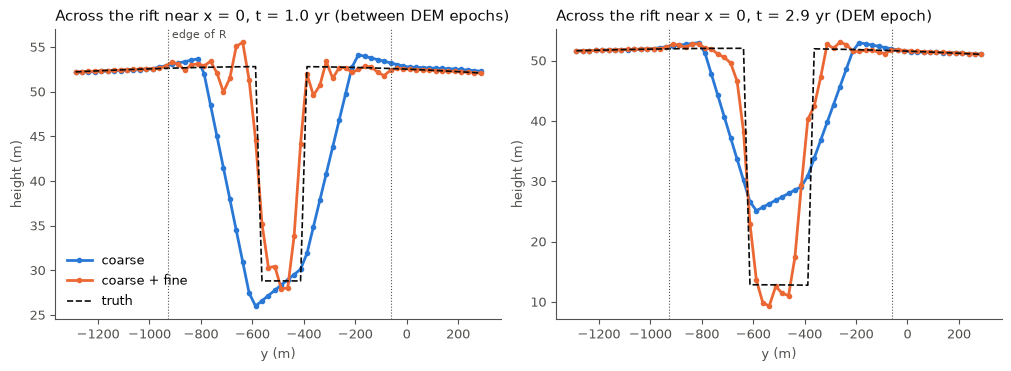

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for this_ax, t, when in zip(ax, [1.0, 2.9], ['between DEM epochs', 'DEM epoch']):
    for label, S, color in [('coarse', S_coarse, c_coarse), ('coarse + fine', S_fine, c_fine)]:
        z_m = model_at(S, xe[ii][order], y_prof, np.zeros_like(y_prof)+t)
        this_ax.plot(y_prof, z_m, color=color, lw=2, label=label, marker='.')
    this_ax.plot(y_prof, z_true(xe[ii][order], y_prof, t), color=ink, lw=1.2, ls='--', label='truth')
    for y_edge in edges:
        this_ax.axvline(y_edge, color=ink2, lw=0.8, ls=':')
    this_ax.set_title(f'Across the rift near x = 0, t = {t} yr ({when})', loc='left', color=ink)
    this_ax.set_xlabel('y (m)'); this_ax.set_ylabel('height (m)')
ax[0].legend(frameon=False, loc='lower left')
ax[0].text(edges[0], ax[0].get_ylim()[1], ' edge of R', color=ink2, va='top', fontsize=8);

## The fine fields

`smooth_fit` returns the fine fields as `S['m']['z0_fine']` and `S['m']['dz_fine']`, on their own grids.  They are NaN outside $R$, and $\delta z_f$ is zero at the reference epoch.  The maps below show that the fine fields carry the rift, but they are noisy along the walls.  Near the east end of the rift's path, $z_{0,f}$ has positive values where the model rises above the surface ahead of the tip, and $\delta z_f$ carries the deepening that follows.  At the edge nodes they are not exactly zero: the model ramps them to zero over one fine-grid cell outside $R$, so the full model stays continuous.

`S['m']` also contains the coarse+fine totals on the fine grids, `z0_total_fine` and `dz_total_fine`, and their rates, `dzdt_total_fine_lag1`.  These are the fields to use for the full model near the rifts.  `S['m']['z0']` and `S['m']['dz']` are the coarse fields only.

fine-grid outputs: ['dz_fine', 'dz_total_fine', 'dzdt_total_fine_lag1', 'z0_fine', 'z0_total_fine']


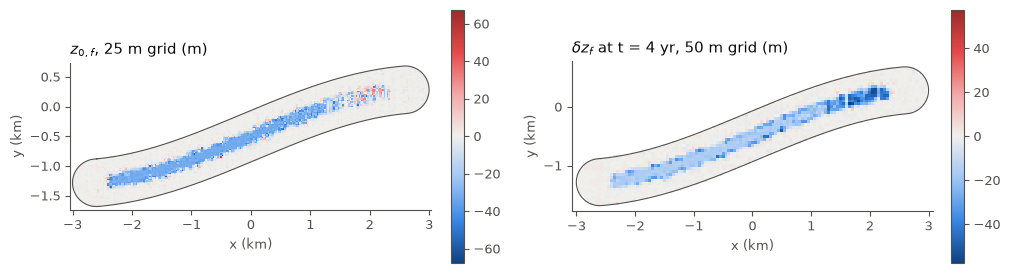

In [8]:
m = S_fine['m']
fig, ax = plt.subplots(1, 2, figsize=(10, 2.9), constrained_layout=True)
delta = {name: S_fine['grids'][name].delta[0] for name in ['z0_fine', 'dz_fine']}
for this_ax, field, vals, title in [
        (ax[0], m['z0_fine'], m['z0_fine'].z0_fine, f"$z_{{0,f}}$, {delta['z0_fine']:.0f} m grid (m)"),
        (ax[1], m['dz_fine'], m['dz_fine'].dz_fine[:, :, -1], f"$\\delta z_f$ at t = 4 yr, {delta['dz_fine']:.0f} m grid (m)")]:
    lim = np.nanmax(np.abs(vals))
    h = this_ax.pcolormesh(field.x/1000, field.y/1000, vals, cmap=div_cmap, norm=TwoSlopeNorm(0, -lim, lim), shading='nearest')
    this_ax.plot(*np.array(region.exterior.xy)/1000, color=ink2, lw=0.8)
    this_ax.set_aspect('equal'); this_ax.set_title(title, loc='left', color=ink)
    this_ax.set_xlabel('x (km)'); this_ax.set_ylabel('y (km)')
    fig.colorbar(h, ax=this_ax, shrink=0.9)
print('fine-grid outputs:', sorted(key for key in m if 'fine' in key))

## Where the models cannot fit the data

To see where the fits fail, we sort the data by their distance from the nearest wall of the trough, $s = |d| - w(t)$, which is negative on the trough floor and positive outside the trough.  For each range of $s$, we compute the percentage of the data that the editing rejected, and the RMS residual, $r = z - z_m$, of all the data, rejected or not.  We leave out the data within 100 m of the west end of the trough and within 300 m of its tip, so that the walls along the sides of the trough dominate.

coarse
   s = -150 to -100 m:  96.3% rejected, RMS residual 28.30 m (all), 1.54 m (kept)
   s = -100 to  -50 m:  97.2% rejected, RMS residual 25.40 m (all), 1.21 m (kept)
   s =  -50 to  -25 m:  97.4% rejected, RMS residual 24.99 m (all), 0.95 m (kept)
   s =  -25 to    0 m:  95.5% rejected, RMS residual 26.78 m (all), 0.89 m (kept)
   s =    0 to   25 m:  89.7% rejected, RMS residual 12.89 m (all), 0.58 m (kept)
   s =   25 to   50 m:  81.4% rejected, RMS residual  9.69 m (all), 0.43 m (kept)
   s =   50 to  100 m:  62.6% rejected, RMS residual  6.22 m (all), 0.53 m (kept)
   s =  100 to  150 m:  36.9% rejected, RMS residual  2.56 m (all), 0.57 m (kept)
   s =  150 to  300 m:  15.8% rejected, RMS residual  0.72 m (all), 0.48 m (kept)
   s =  300 to  600 m:  10.2% rejected, RMS residual  0.50 m (all), 0.47 m (kept)
coarse + fine
   s = -150 to -100 m:   9.3% rejected, RMS residual  3.72 m (all), 0.27 m (kept)
   s = -100 to  -50 m:  19.7% rejected, RMS residual  4.79 m (all), 0.29 m (k

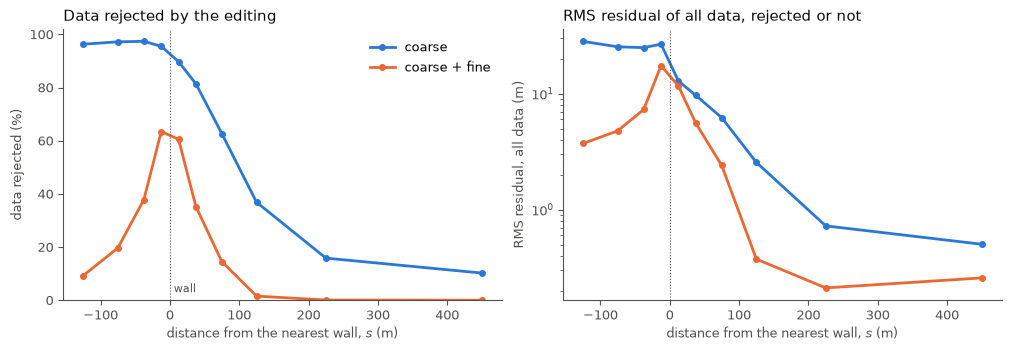

In [9]:
bins = np.array([-150, -100, -50, -25, 0, 25, 50, 100, 150, 300, 600])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), constrained_layout=True)
for label, S, color in [('coarse', S_coarse, c_coarse), ('coarse + fine', S_fine, c_fine)]:
    D = S['data']
    slope = 800*2*np.pi/12000*np.cos(2*np.pi*D.x/12000)
    s = np.abs((D.y - rift_y(D.x))/np.sqrt(1+slope**2)) - (60+20*D.time)
    along = shapely.contains_xy(region, D.x, D.y) & (D.x > -2300) & (D.x < 400+500*D.time-300)
    rejected = ~D.three_sigma_edit
    residual = D.z - D.z_est
    pct_rejected, rms_all, rms_kept = [], [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        these = along & (s >= lo) & (s < hi)
        pct_rejected.append(100*np.mean(rejected[these]))
        rms_all.append(np.sqrt(np.mean(residual[these]**2)))
        rms_kept.append(np.sqrt(np.mean(residual[these & ~rejected]**2)))
    ctrs = (bins[:-1]+bins[1:])/2
    ax[0].plot(ctrs, pct_rejected, color=color, lw=2, marker='o', ms=4, label=label)
    ax[1].plot(ctrs, rms_all, color=color, lw=2, marker='o', ms=4, label=label)
    print(label)
    for lo, hi, p, ra, rk in zip(bins[:-1], bins[1:], pct_rejected, rms_all, rms_kept):
        print(f'   s = {lo:4d} to {hi:4d} m: {p:5.1f}% rejected, RMS residual {ra:5.2f} m (all), {rk:4.2f} m (kept)')
for this_ax in ax:
    this_ax.axvline(0, color=ink2, lw=0.8, ls=':')
    this_ax.set_xlabel('distance from the nearest wall, $s$ (m)')
ax[0].text(0, 2, ' wall', color=ink2, va='bottom', fontsize=8)
ax[0].set_ylabel('data rejected (%)'); ax[0].set_ylim(0, 102)
ax[0].set_title('Data rejected by the editing', loc='left', color=ink)
ax[1].set_yscale('log'); ax[1].set_ylabel('RMS residual, all data (m)')
ax[1].set_title('RMS residual of all data, rejected or not', loc='left', color=ink)
ax[0].legend(frameon=False, loc='upper right');

Within 25 m of a wall, the coarse+fine fit rejects 61 to 63% of the data, and the RMS residual of all the data there is 12 to 17 m.  The model cannot drop by tens of meters between neighboring data, so it misfits the data on both sides of each wall by far more than three times their errors.  The rejections extend about 100 m from the walls (35% from 25 to 50 m outside the trough, 15% from 50 to 100 m), and on the trough floor the fit rejects 9 to 38% of the data, more of them closer to the walls.  The coarse fit rejects 95 to 97% of the data on the trough floor: it treats the trough as a set of outliers.  The data that survive the editing fit the coarse+fine model well (RMS residual 0.2 to 0.3 m), so the residuals of the retained data alone do not reveal the problem.

## Regional averages include the fine fields

The coarse averaging outputs of `smooth_fit` (`avg_dz_*`, `avg_dzdt_*`, `dzdt_lag*`, and the `avg_masks` averages) include the fine fields, unless `fine_grid_args['add_to_coarse_averages']` is False.  For the box $B$, the reported mean height change is

$$
\overline{\delta z}_B(t) = \frac{1}{A_B}\int_B \left[ \delta z(x, y, t) + \delta z_f(x, y, t) \right] dA ,
$$

where $A_B$ is the area of $B$.  `smooth_fit` adds the fine field by spreading it onto the coarse nodes with the transpose of bilinear interpolation, which preserves its area integral.  A negative $\overline{\delta z}_B$ means the box lost volume since $t_{ref}$.

The figure compares the box averages from both fits with the true mean change in $B$.  The gray line is the coarse part of the coarse+fine fit alone: the area-weighted mean of `S['m']['dz']` over the box nodes, which is what the average would be without the fine field.

at t=4 yr: truth -2.48 m, coarse fit -0.99 m, coarse + fine fit -1.98 ± 0.05 m, coarse part alone -0.98 m


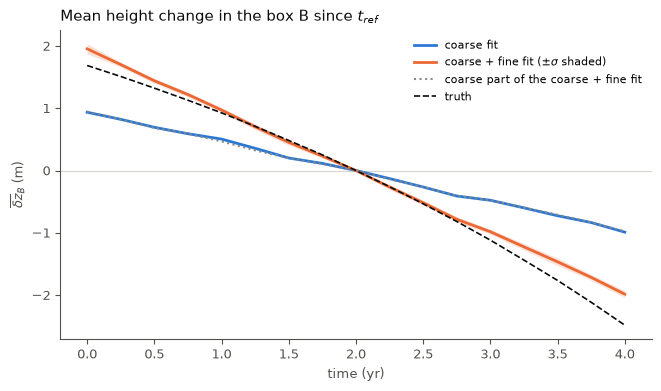

In [10]:
grid_dz = S_fine['grids']['dz']
t_dz = grid_dz.ctrs[2]
in_box = (xe >= box_bounds['x'][0]) & (xe <= box_bounds['x'][1]) & (ye >= box_bounds['y'][0]) & (ye <= box_bounds['y'][1])
truth = [np.mean(z_true(xe[in_box], ye[in_box], t) - z_true(xe[in_box], ye[in_box], t_ref)) for t in t_dz]

# coarse part only: the same box weights applied to the coarse dz nodes
w = box.interp(grid_dz.ctrs[1], grid_dz.ctrs[0], gridded=True)*grid_dz.cell_area
coarse_part = [np.sum(w*S_fine['m']['dz'].dz[:, :, k])/np.sum(w) for k in range(t_dz.size)]

avg_fine = S_fine['m']['box_avg_dz'].box_avg_dz.ravel()
sigma_fine = S_fine['E']['sigma_box_avg_dz'].sigma_box_avg_dz.ravel()
fig, ax = plt.subplots(figsize=(6.5, 3.8), constrained_layout=True)
ax.fill_between(t_dz, avg_fine-sigma_fine, avg_fine+sigma_fine, color=c_fine, alpha=0.2, lw=0)
ax.plot(t_dz, S_coarse['m']['box_avg_dz'].box_avg_dz.ravel(), color=c_coarse, lw=2, label='coarse fit')
ax.plot(t_dz, avg_fine, color=c_fine, lw=2, label='coarse + fine fit ($\\pm\\sigma$ shaded)')
ax.plot(t_dz, coarse_part, color='#8a8984', lw=1.5, ls=':', label='coarse part of the coarse + fine fit')
ax.plot(t_dz, truth, color=ink, lw=1.2, ls='--', label='truth')
ax.axhline(0, color='#d6d5d0', lw=0.8, zorder=0)
ax.set_xlabel('time (yr)'); ax.set_ylabel('$\\overline{\\delta z}_B$ (m)')
ax.set_title('Mean height change in the box B since $t_{ref}$', loc='left', color=ink)
ax.legend(frameon=False, fontsize=8)
print(f'at t=4 yr: truth {truth[-1]:.2f} m, coarse fit {S_coarse["m"]["box_avg_dz"].box_avg_dz.ravel()[-1]:.2f} m, '
      f'coarse + fine fit {avg_fine[-1]:.2f} ± {sigma_fine[-1]:.2f} m, coarse part alone {coarse_part[-1]:.2f} m')

From t = 1 to 2.75 yr, the coarse+fine average is within 0.05 m of the true mean change, about its error estimate.  At t = 0 it overestimates the change by 0.27 m, three times its error estimate, and after t = 2.75 yr it falls behind the truth: at t = 4 yr it is 0.50 m short, nine times its error estimate.  Much of the rift's growth happens at its walls, which move outward, and at its tip, where the editing rejects many of the data and the model spreads the deepening over the whole record.  Of the rift's own volume change, the change of the true mean minus that of the background (−1.51 m at t = 4 yr), the coarse+fine fit recovers about two thirds.  The coarse fit's average is the same as the coarse part of the coarse+fine fit, and it matches the change of the background alone (−0.97 m at t = 4 yr): the coarse fit rejects nearly all of the data on the trough floor, so it records none of the rift's volume change.  As in `fine_grid_demo.ipynb`, the error estimate assumes random data errors and a surface that follows the statistics of the constraints, and uses only the data that survive the editing, so it does not include these errors.

## Error estimates

With `compute_E=True`, `S['E']` contains errors for each output (`sigma_z0_fine`, `sigma_dz_fine`, `sigma_z0_total_fine`, ...).  The coarse and fine fields trade off against each other inside $R$, so their errors are correlated, and the error of a component can be larger than the error of the total.  Use the errors of the totals for the full model.

In [11]:
E = S_fine['E']
for key in ['sigma_z0_fine', 'sigma_z0_total_fine', 'sigma_dz_fine', 'sigma_dz_total_fine']:
    vals = getattr(E[key], key)
    print(f'{key:22s}: median {np.nanmedian(vals[vals > 0]):.2f} m')

sigma_z0_fine         : median 1.87 m
sigma_z0_total_fine   : median 1.63 m
sigma_dz_fine         : median 1.03 m
sigma_dz_total_fine   : median 1.04 m


## Summary

When the surface has features that neither the coarse nor the fine grids can represent, such as the vertical walls of this rift:

- the coarse+fine model spreads each wall over 50 to 100 m, and oscillates next to the walls by a few meters;
- the misfits near the walls are many times the data errors, so the editing rejects most of the data within 25 m of the walls and some out to 100 m, and the coarse fit rejects nearly all of the data on the trough floor;
- the rejected data no longer constrain the model, so the model misses part of the rift's growth: here, about a third of its volume change;
- the error estimates do not include these effects, and the residuals of the retained data look normal.

This notebook does not test remedies.  Finer fine grids help only in part: with 50 m and 100 m nodes, the coarse+fine fit rejected 26% of the data in $R$, compared with 15% here.  Other possible remedies are weaker fine-grid constraints, which let the model represent steeper walls, or larger data errors near the walls, which keep the editing from rejecting the data there.